<a href="https://colab.research.google.com/github/SaifWael9/leukemia-detection/blob/main/Leukemia_ResNet50.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# STEP 0: Connect to Google Drive & Setup Checkpoints
from google.colab import drive
import tensorflow as tf

drive.mount('/content/drive')

checkpoint_path = "/content/drive/MyDrive/Best_Leukemia_Model.keras"
checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_path,
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

Mounted at /content/drive


In [ ]:
# STEP 1: Download and Extract Dataset
!pip install -q kaggle
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d andrewmvd/leukemia-classification
!unzip -q leukemia-classification.zip -d leukemia_data
!rm leukemia-classification.zip
print("Dataset ready!")

Dataset URL: https://www.kaggle.com/datasets/andrewmvd/leukemia-classification
License(s): other
100% 867M/867M [00:10<00:00, 89.2MB/s]

Dataset ready!


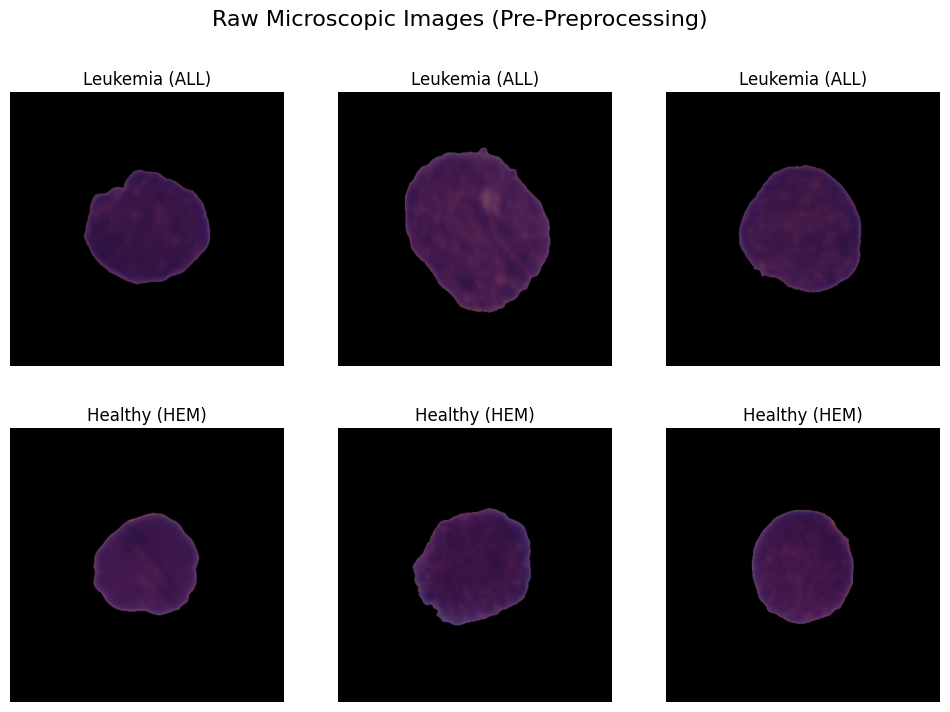

In [ ]:
# STEP 2: PRE-PREPROCESSING Visualization (Raw Images)
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random
import os

base_train_dir = 'leukemia_data/C-NMC_Leukemia/training_data/fold_0/'
all_dir = os.path.join(base_train_dir, 'all')
hem_dir = os.path.join(base_train_dir, 'hem')

all_imgs = random.sample(os.listdir(all_dir), 3)
hem_imgs = random.sample(os.listdir(hem_dir), 3)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
fig.suptitle('Raw Microscopic Images (Pre-Preprocessing)', fontsize=16)

for i, img_name in enumerate(all_imgs):
    axes[0, i].imshow(mpimg.imread(os.path.join(all_dir, img_name)))
    axes[0, i].set_title("Leukemia (ALL)")
    axes[0, i].axis('off')

for i, img_name in enumerate(hem_imgs):
    axes[1, i].imshow(mpimg.imread(os.path.join(hem_dir, img_name)))
    axes[1, i].set_title("Healthy (HEM)")
    axes[1, i].axis('off')
plt.show()

In [ ]:
# STEP 3: Elite Data Preparation
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet50 import preprocess_input

base_dir = 'leukemia_data/C-NMC_Leukemia/'
data = []
train_dir = os.path.join(base_dir, 'training_data')
for fold in os.listdir(train_dir):
    fold_path = os.path.join(train_dir, fold)
    if os.path.isdir(fold_path):
        for label in ['all', 'hem']:
            class_dir = os.path.join(fold_path, label)
            if os.path.isdir(class_dir):
                for img_file in os.listdir(class_dir):
                    data.append({'filepath': os.path.join(class_dir, img_file), 'label': label})

df = pd.DataFrame(data)
train_df, val_df = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=42)

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=40, vertical_flip=True, horizontal_flip=True, zoom_range=0.2
)
val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_dataframe(train_df, x_col='filepath', y_col='label', target_size=(224, 224), batch_size=32, class_mode='categorical')
val_generator = val_datagen.flow_from_dataframe(val_df, x_col='filepath', y_col='label', target_size=(224, 224), batch_size=32, class_mode='categorical', shuffle=False)

Found 7462 validated image filenames belonging to 2 classes.
Found 3199 validated image filenames belonging to 2 classes.


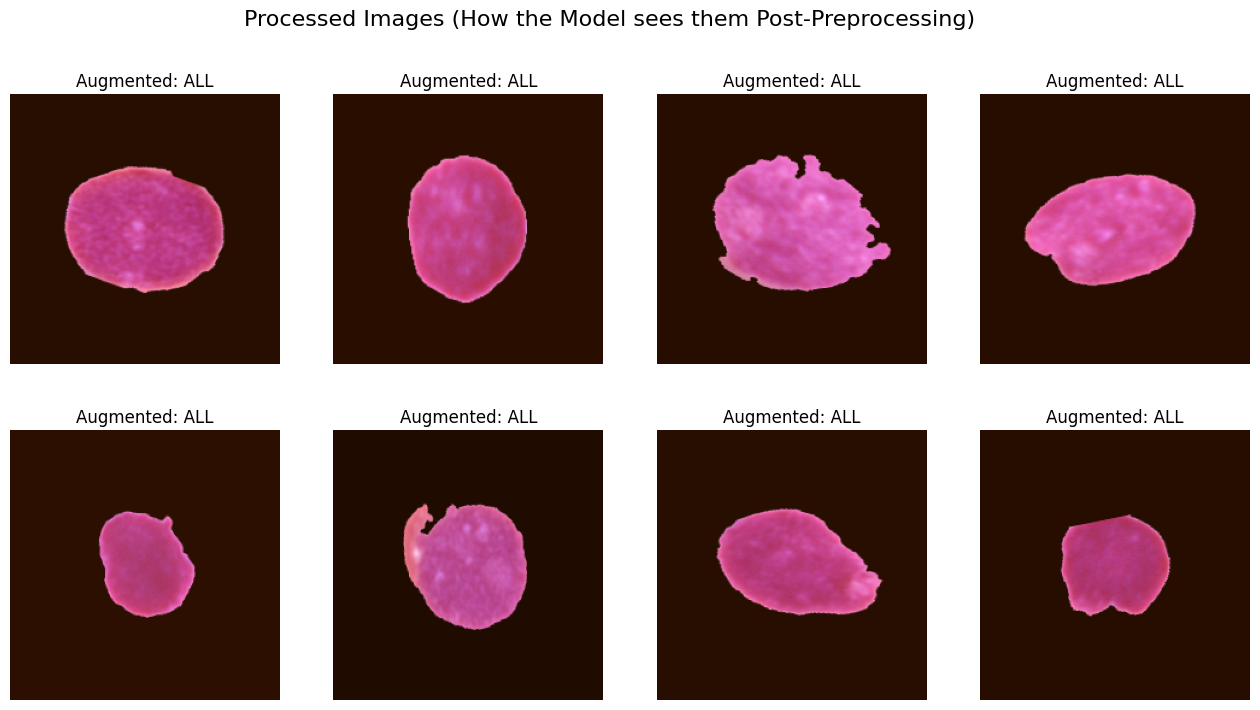

In [ ]:
# STEP 4: POST-PREPROCESSING Visualization (Processed Images)
images, labels = next(train_generator)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Processed Images (How the Model sees them Post-Preprocessing)', fontsize=16)
class_labels = list(train_generator.class_indices.keys())

for i, ax in enumerate(axes.flat):
    img_display = (images[i] - images[i].min()) / (images[i].max() - images[i].min())
    ax.imshow(img_display)
    label_idx = np.argmax(labels[i])
    ax.set_title(f"Augmented: {class_labels[label_idx].upper()}")
    ax.axis('off')
plt.show()

In [ ]:
# STEP 5: Model Building & Warmup Training
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adamax

base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
x = GlobalAveragePooling2D()(base_model.output)
x = Dropout(0.5)(x)
x = Dense(256, activation='relu')(x)
predictions = Dense(2, activation='softmax')(x)
model = Model(inputs=base_model.input, outputs=predictions)

for layer in base_model.layers: layer.trainable = False
model.compile(optimizer=Adamax(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])
model.fit(train_generator, validation_data=val_generator, epochs=5)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/5
234/234 ━━━━━━━━━━━━━━━━━━━━ 166s 642ms/step - accuracy: 0.7548 - loss: 0.5456 - val_accuracy: 0.8109 - val_loss: 0.4468
Epoch 2/5
234/234 ━━━━━━━━━━━━━━━━━━━━ 129s 549ms/step - accuracy: 0.7904 - loss: 0.4856 - val_accuracy: 0.7912 - val_loss: 0.4633
Epoch 3/5
234/234 ━━━━━━━━━━━━━━━━━━━━ 122s 522ms/step - accuracy: 0.7960 - loss: 0.4663 - val_accuracy: 0.7721 - val_loss: 0.5077
Epoch 4/5
234/234 ━━━━━━━━━━━━━━━━━━━━ 125s 533ms/step - accuracy: 0.7956 - loss: 0.4654 - val_accuracy: 0.7965 - val_loss: 0.4603
Epoch 5/5
234/234 ━━━━━━━━━━━━━━━━━━━━ 132s 563ms/step - accuracy: 0.8002 - loss: 0.4605 - val_accuracy: 0.8103 - val_loss: 0.4428


In [ ]:
# STEP 6: Elite Fine-Tuning Phase
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.optimizers import Adam

weights = compute_class_weight('balanced', classes=np.unique(train_generator.classes), y=train_generator.classes)
class_weights = dict(enumerate(weights))

for layer in base_model.layers:
    layer.trainable = not isinstance(layer, tf.keras.layers.BatchNormalization)

lr_schedule = tf.keras.optimizers.schedules.CosineDecay(1e-5, len(train_generator) * 45)
model.compile(optimizer=Adam(lr_schedule), loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1), metrics=['accuracy'])

high_acc_stop = tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True)
history_finetune = model.fit(train_generator, validation_data=val_generator, epochs=45, class_weight=class_weights, callbacks=[high_acc_stop, checkpoint_callback])

Epoch 1/45
234/234 ━━━━━━━━━━━━━━━━━━━━ 0s 630ms/step - accuracy: 0.7701 - loss: 0.5656
Epoch 1: val_accuracy improved from None to 0.85120, saving model to /content/drive/MyDrive/Best_Leukemia_Model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Best_Leukemia_Model.keras
234/234 ━━━━━━━━━━━━━━━━━━━━ 213s 735ms/step - accuracy: 0.7854 - loss: 0.5444 - val_accuracy: 0.8512 - val_loss: 0.4599
Epoch 2/45
234/234 ━━━━━━━━━━━━━━━━━━━━ 0s 577ms/step - accuracy: 0.8162 - loss: 0.5028
Epoch 2: val_accuracy improved from 0.85120 to 0.86496, saving model to /content/drive/MyDrive/Best_Leukemia_Model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Best_Leukemia_Model.keras
234/234 ━━━━━━━━━━━━━━━━━━━━ 148s 630ms/step - accuracy: 0.8239 - loss: 0.4915 - val_accuracy: 0.8650 - val_loss: 0.4432
Epoch 3/45
234/234 ━━━━━━━━━━━━━━━━━━━━ 0s 578ms/step - accuracy: 0.8353 - loss: 0.4758
Epoch 3: val_accuracy did not improve from 0.86496
234/234 ━━━━━━━━━━━━━━━━━━━━ 150s 63

100/100 ━━━━━━━━━━━━━━━━━━━━ 20s 138ms/step
              precision    recall  f1-score   support

           0       0.93      0.98      0.95      2182
           1       0.95      0.83      0.89      1017

    accuracy                           0.93      3199
   macro avg       0.94      0.91      0.92      3199
weighted avg       0.93      0.93      0.93      3199



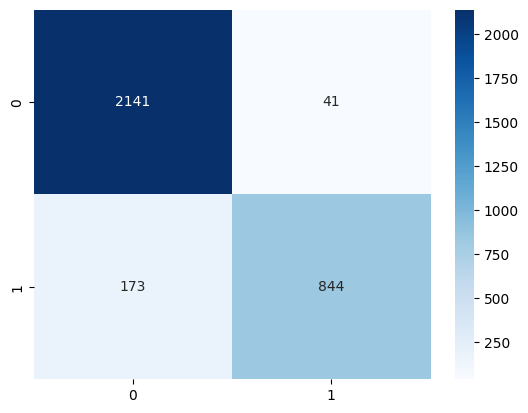

In [ ]:
# STEP 7: Final Metrics & Confusion Matrix
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

val_generator.reset()
y_pred = np.argmax(model.predict(val_generator), axis=1)
y_true = val_generator.classes
print(classification_report(y_true, y_pred))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues')
plt.show()

In [ ]:
# STEP 8: Save Outputs Locally
from google.colab import files
model.save('Leukemia_Final_Model.keras')
files.download('Leukemia_Final_Model.keras')
print("Model saved and download triggered.")

In [ ]:
# STEP 9: Upload and Predict from PC
from google.colab import files
from tensorflow.keras.preprocessing import image

print("Select a blood smear image from your computer:")
uploaded = files.upload()

for fn in uploaded.keys():
    img = image.load_img(fn, target_size=(224, 224))
    plt.imshow(img); plt.axis('off'); plt.show()
    x = preprocess_input(image.img_to_array(img))
    x = np.expand_dims(x, axis=0)
    preds = model.predict(x)
    print(f"Prediction: {'LEUKEMIA' if np.argmax(preds) == 0 else 'HEALTHY'} ({np.max(preds)*100:.2f}%)")

Select a blood smear image from your computer:


Saving test_original_20160720_232510.jpg_ce067646-d645-467d-9915-5f5ea589ce56.jpg to test_original_20160720_232510.jpg_ce067646-d645-467d-9915-5f5ea589ce56.jpg


NameError: name 'plt' is not defined